In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready to use!')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready to use!


In [ ]:
# STEP-1: Define the state
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class AgentState(TypedDict):
    x: int

print('Graph state is ready..')

Graph state is ready..


In [32]:
# STEP-2: Define the nodes
def assistant(state: AgentState) -> dict:
    """One graph node: call the model using current messages"""
    print(f'State in node 1: {state}')
    state['x'] = 70
    return state

def assistant_2(state: AgentState) -> dict:
    """One graph node: call the model using current messages"""
    print(f'State in node 2: {state}')
    temp_x = state['x']
    print(f'Node 2: x = {temp_x}')
    return state

print('Graph Nodes are ready')

Graph Nodes are ready


Graph is ready...


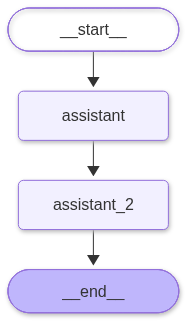

In [33]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant", assistant)
graph_builder.add_node("assistant_2", assistant_2)

# Add edges
graph_builder.add_edge(START, "assistant")
graph_builder.add_edge("assistant", "assistant_2")
graph_builder.add_edge("assistant_2", END)

graph = graph_builder.compile()
print('Graph is ready...')
graph

In [34]:
response = graph.invoke({
    "x": 50
})
response

State in node 1: {'x': 50}
State in node 2: {'x': 70}
Node 2: x = 70


{'x': 70}

In [35]:
response = graph.invoke({
    
})
response

State in node 1: {}
State in node 2: {'x': 70}
Node 2: x = 70


{'x': 70}

In [36]:
# STEP-1: Define the state
from typing import TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages

class AgentState2(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('Graph state 2 is ready..')

Graph state 2 is ready..


In [40]:
# STEP-2: Define the nodes
def assistant(state: AgentState2) -> dict:
    """One graph node: call the model using current messages"""
    response = model.invoke(state['messages'])
    return {"messages": [response]}

print('Graph Nodes are ready')

Graph Nodes are ready


Graph is ready...


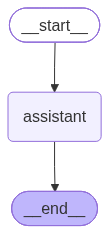

In [41]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState2)

# Node registration
graph_builder.add_node("assistant", assistant)

# Add edges
graph_builder.add_edge(START, "assistant")
graph_builder.add_edge("assistant", END)

graph = graph_builder.compile()
print('Graph is ready...')
graph

In [42]:
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "I am Tom"}
    ]
})
response

{'messages': [HumanMessage(content='I am Tom', additional_kwargs={}, response_metadata={}, id='a7d27861-fb77-4ec0-aa6a-d1e4c97a4a50'),
  AIMessage(content='Nice to meet you, Tom! How can I help you today?', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T09:53:42.042503342Z', 'done': True, 'done_reason': 'stop', 'total_duration': 322713380, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 62, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bad-d048-7c73-a786-9a4be36027ab-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 62, 'total_tokens': 132})]}

In [43]:
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "What is my name?"}
    ]
})
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='7b20e9a8-ef8b-4b0a-8db4-7c874689c9a4'),
  AIMessage(content='I don’t actually know your name. Could you let me know what you’d like me to call you?', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T09:54:04.101049851Z', 'done': True, 'done_reason': 'stop', 'total_duration': 590180235, 'load_duration': None, 'prompt_eval_count': 72, 'prompt_eval_duration': None, 'eval_count': 93, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bae-25e5-7343-8865-73a1bc536c36-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 93, 'total_tokens': 165})]}

Graph is ready...


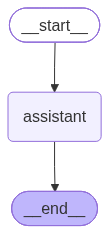

In [49]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

graph_builder = StateGraph(AgentState2)

short_term_memory = MemorySaver()

# Node registration
graph_builder.add_node("assistant", assistant)

# Add edges
graph_builder.add_edge(START, "assistant")
graph_builder.add_edge("assistant", END)

graph = graph_builder.compile(checkpointer=short_term_memory)
print('Graph is ready...')
graph

In [50]:
thread_global_warming = {"configurable": {"thread_id": "Global_warming"}}
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "I am Tom"}
    ]
}, config=thread_global_warming)
response

{'messages': [HumanMessage(content='I am Tom', additional_kwargs={}, response_metadata={}, id='1e0c4bb3-39be-441f-836e-fdf406927fbc'),
  AIMessage(content='Nice to meet you, Tom! How can I assist you today?', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:03:31.768727065Z', 'done': True, 'done_reason': 'stop', 'total_duration': 669510976, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 53, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bb6-ceea-7730-8786-356ca8c7eb27-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 53, 'total_tokens': 123})]}

In [51]:
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "What is my name?"}
    ]
}, config=thread_global_warming)
response

{'messages': [HumanMessage(content='I am Tom', additional_kwargs={}, response_metadata={}, id='1e0c4bb3-39be-441f-836e-fdf406927fbc'),
  AIMessage(content='Nice to meet you, Tom! How can I assist you today?', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:03:31.768727065Z', 'done': True, 'done_reason': 'stop', 'total_duration': 669510976, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 53, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bb6-ceea-7730-8786-356ca8c7eb27-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 53, 'total_tokens': 123}),
  HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='242c735d-df08-4866-8faf-0de5b9babf7d'),
  AIMessage(content='Your name is Tom.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'creat

In [52]:
thread_tourist_places = {"configurable": {"thread_id": "Tourist_Places"}}
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "What is my name?"}
    ]
}, config=thread_tourist_places)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='2224ed94-0e6c-40a9-b4d3-a71a232df048'),
  AIMessage(content='I don’t have any information about your name. If you’d like me to address you personally, just let me know what you’d like to be called!', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:04:36.872690678Z', 'done': True, 'done_reason': 'stop', 'total_duration': 437439083, 'load_duration': None, 'prompt_eval_count': 72, 'prompt_eval_duration': None, 'eval_count': 73, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bb7-ce24-7ab1-a482-4447ba01c6d4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 73, 'total_tokens': 145})]}

Graph is ready...


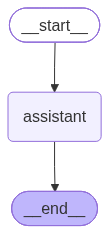

In [ ]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
import sqlite3

graph_builder = StateGraph(AgentState2)

# In RAM
# short_term_memory = MemorySaver()

# In database
db_path = "global_warming.db"
sqlite_connection = sqlite3.connect(db_path, check_same_thread=False)
short_term_memory = SqliteSaver(sqlite_connection)

# Node registration
graph_builder.add_node("assistant", assistant)

# Add edges
graph_builder.add_edge(START, "assistant")
graph_builder.add_edge("assistant", END)

graph = graph_builder.compile(checkpointer=short_term_memory)
print('Graph is ready...')
graph

In [54]:
thread_global_warming = {"configurable": {"thread_id": "Global_warming"}}
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "I am Tom"}
    ]
}, config=thread_global_warming)
response

{'messages': [HumanMessage(content='I am Tom', additional_kwargs={}, response_metadata={}, id='4a58d2a5-8a1f-4ad2-9275-d1d2169da052'),
  AIMessage(content='Nice to meet you, Tom! How can I assist you today?', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:11:32.921060847Z', 'done': True, 'done_reason': 'stop', 'total_duration': 539930606, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 64, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bbe-269d-78b3-b1b0-e4c75504261a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 64, 'total_tokens': 134})]}

In [55]:
response = graph.invoke({
    "messages": [
        {"role": "user", "content": "What is my name?"}
    ]
}, config=thread_global_warming)
response

{'messages': [HumanMessage(content='I am Tom', additional_kwargs={}, response_metadata={}, id='4a58d2a5-8a1f-4ad2-9275-d1d2169da052'),
  AIMessage(content='Nice to meet you, Tom! How can I assist you today?', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:11:32.921060847Z', 'done': True, 'done_reason': 'stop', 'total_duration': 539930606, 'load_duration': None, 'prompt_eval_count': 70, 'prompt_eval_duration': None, 'eval_count': 64, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bbe-269d-78b3-b1b0-e4c75504261a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 70, 'output_tokens': 64, 'total_tokens': 134}),
  HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='648edf5b-ea20-421c-b360-6b4ca52d15ee'),
  AIMessage(content='Your name is Tom.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'creat

In [57]:
from langgraph.config import get_store, get_config
from langchain_community.tools import tool

@tool
def save_memory(fact: str) -> str:
    """Save an important fact about the user for future conversations
    (e.g. their name, workplace, or a stated preference)."""
    store = get_store()
    user_id = get_config()["configurable"]["user_id"]
    store.put(("memories", user_id), fact[:40], {"text": fact})
    return f"Saved: {fact}"

@tool
def recall_memories(query: str) -> str:
    """Search saved facts about the user relevant to the query.
    ALWAYS call this before claiming you don't know something about the user."""
    store = get_store()
    user_id = get_config()["configurable"]["user_id"]
    results = store.search(("memories", user_id), query=query, limit=5)
    if not results:
        return "No relevant memories found."
    return "\n".join(f"- {r.value['text']}" for r in results)

print("Memory tools ready: save_memory, recall_memories")


Memory tools ready: save_memory, recall_memories


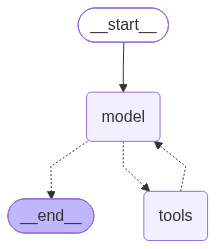

In [58]:
from langgraph.store.memory import InMemoryStore
from langgraph.store.sqlite import SqliteStore
from langchain.agents import create_agent

long_term_memory = InMemoryStore()

agent = create_agent(
    model=model,
    tools=[save_memory, recall_memories],
    store=long_term_memory,
    system_prompt=(
        "You are a helpful assistant with long-term memory. "
        "When the user shares a personal fact, call save_memory, then briefly confirm. "
        "When asked what you know about the user, ALWAYS call recall_memories first. "
        "Your final answer MUST be based only on the tool output returned -- restate those facts plainly. "
        "Never say you don't know something if the tool result contains it."
    )
)
agent


In [59]:
thread_global_warming_user_tom = {"configurable": {"thread_id": "Global_warming", "user_id": "tom"}}
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "I am Tom"}
    ]
}, config=thread_global_warming_user_tom)
response

{'messages': [HumanMessage(content='I am Tom', additional_kwargs={}, response_metadata={}, id='e81b21d3-44c7-4f9b-aacb-6cf596adb135'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:21:44.745059127Z', 'done': True, 'done_reason': 'stop', 'total_duration': 355050986, 'load_duration': None, 'prompt_eval_count': 263, 'prompt_eval_duration': None, 'eval_count': 49, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bc7-7d37-7e73-baf1-8f867038203d-0', tool_calls=[{'name': 'save_memory', 'args': {'fact': "User's name is Tom"}, 'id': 'fb57f4ec-9843-4cb6-aace-2a64cdd79eea', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 263, 'output_tokens': 49, 'total_tokens': 312}),
  ToolMessage(content="Saved: User's name is Tom", name='save_memory', id='592a4708-90da-4236-bbbf-19ceac0cb5d1', tool_call_id='fb57f4ec-9843-4cb6-aace-2a64cdd79e

In [60]:
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "What is my name?"}
    ]
}, config=thread_global_warming_user_tom)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='db229483-0624-4b09-ba33-b31fe815c7a8'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:22:20.192600115Z', 'done': True, 'done_reason': 'stop', 'total_duration': 499211773, 'load_duration': None, 'prompt_eval_count': 265, 'prompt_eval_duration': None, 'eval_count': 84, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bc8-0515-7672-b797-3914c6c78aae-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'name'}, 'id': 'bb118153-fffd-43da-9f4f-c9cf64bdf82e', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 265, 'output_tokens': 84, 'total_tokens': 349}),
  ToolMessage(content="- User's name is Tom", name='recall_memories', id='1a0a670f-8b15-4547-9723-22ffd4bf21eb', tool_call_id='bb118153-fffd-43da-9f4f-c9cf64bdf82e

In [61]:
thread_tourist_places_user_tom = {"configurable": {"thread_id": "Tourist_Places", "user_id": "tom"}}
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "What is my name?"}
    ]
}, config=thread_tourist_places_user_tom)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='96bb20d8-ab66-4b17-b4fc-13c202dd5300'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:23:49.314643392Z', 'done': True, 'done_reason': 'stop', 'total_duration': 404078885, 'load_duration': None, 'prompt_eval_count': 265, 'prompt_eval_duration': None, 'eval_count': 49, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bc9-60cd-7f01-a1dc-5c2ef2bcbc29-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'name'}, 'id': '79ea56a7-ec5c-4869-b125-77638849f192', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 265, 'output_tokens': 49, 'total_tokens': 314}),
  ToolMessage(content="- User's name is Tom", name='recall_memories', id='65c8527a-979a-46e4-8e72-9ed50fe87045', tool_call_id='79ea56a7-ec5c-4869-b125-77638849f192

In [62]:
thread_tourist_places_user_jerry = {"configurable": {"thread_id": "Tourist_Places", "user_id": "jerry"}}
response = agent.invoke({
    "messages": [
        {"role": "user", "content": "What is my name?"}
    ]
}, config=thread_tourist_places_user_jerry)
response

{'messages': [HumanMessage(content='What is my name?', additional_kwargs={}, response_metadata={}, id='eab5a384-ab4d-4084-9819-eb2e5d6584ef'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-11-02T10:24:59.673950578Z', 'done': True, 'done_reason': 'stop', 'total_duration': 745133991, 'load_duration': None, 'prompt_eval_count': 265, 'prompt_eval_duration': None, 'eval_count': 159, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a19bca-758d-7893-a40e-acdcd932ff1e-0', tool_calls=[{'name': 'recall_memories', 'args': {'query': 'name'}, 'id': '0ae93981-e49e-473d-9854-15c61db711b8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 265, 'output_tokens': 159, 'total_tokens': 424}),
  ToolMessage(content='No relevant memories found.', name='recall_memories', id='2c45ed96-9533-4ecb-b343-bd976e014dd2', tool_call_id='0ae93981-e49e-473d-9854-15c